Conjunto de datos
dynamic_pricing.csv (Kaggle), trabajando con las variables definidas en la
Tabla 2 de esta guía: Expected_Ride_Duration, Average_Ratings,
Historical_Cost_of_Ride, Customer_Loyalty_Status y Vehicle_Type.

Objetivo

Realizar un análisis estadístico de tipo explicativo e inferencial a partir del archivo " Anexo 1 - Base de Datos dynamic_pricing.csv".

In [1]:
#1. Importamos las librerías que vamos a usar hasta el momento para leer el Data Set
import pandas as pd

# 2. Obtenemos el archivo y lo guardamos en dataset
dataset = ("C:/Users/Aturd/OneDrive/Escritorio/Maestría/semestre_2/Estadística/tarea_2/Tarea_2/data/Anexo 1 - Base de Datos dynamic_pricing (3).csv")

# 3. lo pasamos en un DataFrame de Pandas
df = pd.read_csv(dataset)

# Mostrar los datos
df.head()
#revisamos los datos

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


In [2]:
df.describe() # estadísticas descriptivas de las variables numéricas

,Number_of_Riders,Number_of_Drivers,Number_of_Past_Rides,Average_Ratings,Expected_Ride_Duration,Historical_Cost_of_Ride
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,60.372000,27.076000,50.031000,4.257220,99.58800,372.502623
std,23.701506,19.068346,29.313774,0.435781,49.16545,187.158756
min,20.000000,5.000000,0.000000,3.500000,10.00000,25.993449
25%,40.000000,11.000000,25.000000,3.870000,59.75000,221.365202
50%,60.000000,22.000000,51.000000,4.270000,102.00000,362.019426
75%,81.000000,38.000000,75.000000,4.632500,143.00000,510.497504
max,100.000000,89.000000,100.000000,5.000000,180.00000,836.116419


In [3]:
df.info() # información general del DataFrame, incluyendo el número de entradas, columnas, tipos de datos y valores nulos.

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Number_of_Riders         1000 non-null   int64  
 1   Number_of_Drivers        1000 non-null   int64  
 2   Location_Category        1000 non-null   str    
 3   Customer_Loyalty_Status  1000 non-null   str    
 4   Number_of_Past_Rides     1000 non-null   int64  
 5   Average_Ratings          1000 non-null   float64
 6   Time_of_Booking          1000 non-null   str    
 7   Vehicle_Type             1000 non-null   str    
 8   Expected_Ride_Duration   1000 non-null   int64  
 9   Historical_Cost_of_Ride  1000 non-null   float64
dtypes: float64(2), int64(4), str(4)
memory usage: 78.2 KB


# 2.1 Teorema Central del Límite (TCL) y su aplicación práctica 

In [4]:
df.copy() # hacemos una copia del DataFrame para trabajar con ella y no modificar el original

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422
...,...,...,...,...,...,...,...,...,...,...
995,33,23,Urban,Gold,24,4.21,Morning,Premium,11,91.389526
996,84,29,Urban,Regular,92,4.55,Morning,Premium,94,424.155987
997,44,6,Suburban,Gold,80,4.13,Night,Premium,40,157.364830
998,53,27,Suburban,Regular,78,3.63,Night,Premium,58,279.095048


In [5]:
tcl=df['Expected_Ride_Duration'] # seleccionamos la columna de duración esperada

print(tcl)

0       90
1       43
2       76
3      134
4      149
      ... 
995     11
996     94
997     40
998     58
999    147
Name: Expected_Ride_Duration, Length: 1000, dtype: int64


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Configurar una semilla  para que el experimento sea reproducible
np.random.seed(42)


poblacion_duracion = tcl

# Parámetros del experimento solicitado
n = 30           # Tamaño de cada muestra
replicas = 1000  # Cantidad de veces que repetiremos el muestreo

# Simular múltiples muestras y calcular la media de cada una
medias_muestrales = []
for _ in range(replicas):
    # Tomamos una muestra aleatoria de tamaño n de nuestra población
    muestra = np.random.choice(poblacion_duracion, size=n, replace=False)
    # Calculamos la media de esa muestra y la guardamos
    medias_muestrales.append(np.mean(muestra))

# Convertir a arreglo de NumPy para facilitar operaciones gráficas
medias_muestrales = np.array(medias_muestrales)




C:\Users\Aturd\AppData\Local\Temp\ipykernel_13372\3872576792.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right')


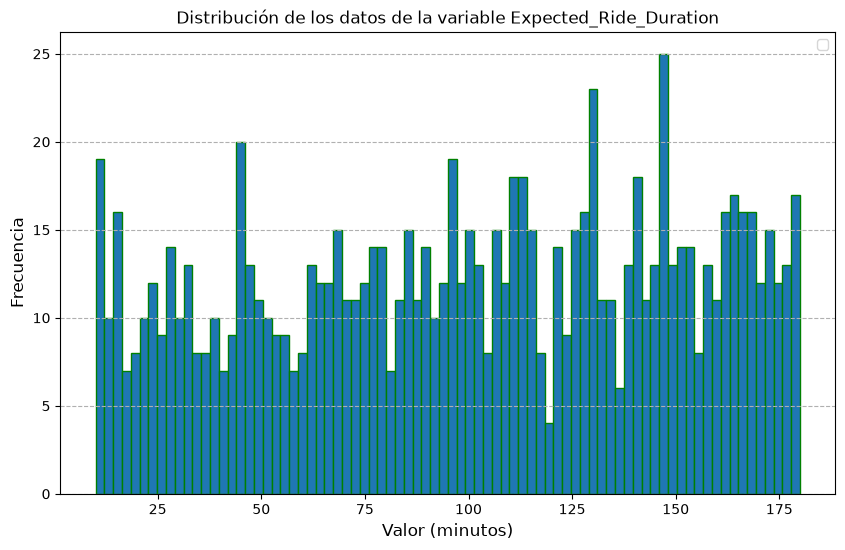

In [7]:
# Dibujar el histograma de las medias obtenidas
import os

#nos ayuda a guardar en la carpeta outputs fuera de donde estamos trabajando
folder_path = os.path.join("..", "outputs")
os.makedirs(folder_path, exist_ok=True)


#  Graficar la distribución de las medias muestrales
plt.figure(figsize=(10, 6))


plt.hist(poblacion_duracion, bins=80, edgecolor='green')
# personalizar el gráfico
plt.title('Distribución de los datos de la variable Expected_Ride_Duration')
plt.xlabel('Valor (minutos)', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--')


# Guardar y mostrar
filename = "Distribución de los datos de la variable Expected_Ride_Duration.png"
file_path = os.path.join(folder_path, filename)
plt.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()

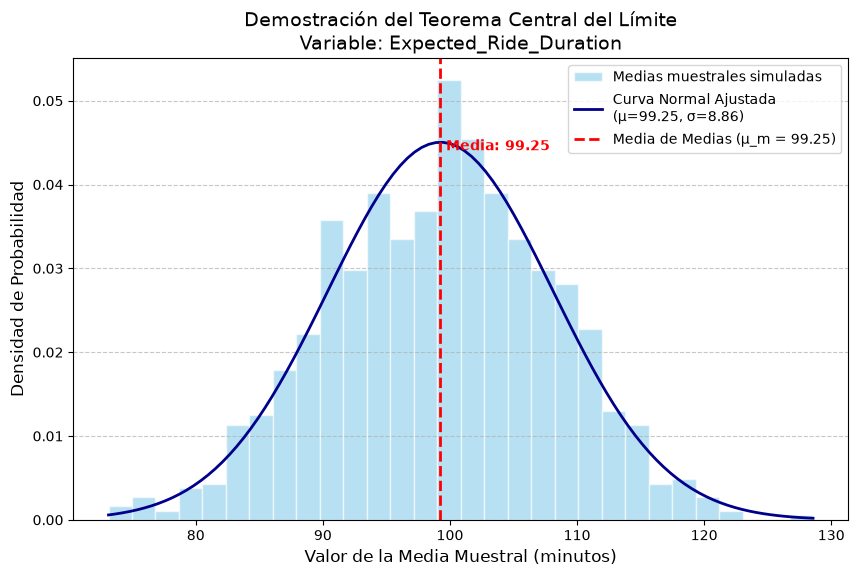

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats


#nos ayuda a guardar en la carpeta outputs fuera de donde estamos trabajando
folder_path = os.path.join("..", "outputs")
os.makedirs(folder_path, exist_ok=True)


#  Graficar la distribución de las medias muestrales
plt.figure(figsize=(10, 6))

# Dibujar el histograma de las medias obtenidas
count, bins, ignored = plt.hist(medias_muestrales, bins=30, density=True, 
                                alpha=0.6, color='skyblue', edgecolor='white', 
                                label='Medias muestrales simuladas')

# Curva teórica Normal para verificar visualmente el ajuste empírico
mu_medias = np.mean(medias_muestrales)
sigma_medias = np.std(medias_muestrales)
x = np.linspace(min(medias_muestrales), max(medias_muestrales), 100)
plt.plot(x, stats.norm.pdf(x, mu_medias, sigma_medias), color='darkblue', 
         linewidth=2, label=f'Curva Normal Ajustada\n(μ={mu_medias:.2f}, σ={sigma_medias:.2f})')


## Línea vertical para representar la media general 🔴
plt.axvline(mu_medias, color='red', linestyle='--', linewidth=2, 
            label=f'Media de Medias (μ_m = {mu_medias:.2f})')

y_max = plt.gca().get_ylim()[1]
plt.text(mu_medias + (sigma_medias*0.05), y_max * 0.8, f'Media: {mu_medias:.2f}', 
         color='red', fontweight='bold', fontsize=10)


# Personalización del gráfico
plt.title('Demostración del Teorema Central del Límite\nVariable: Expected_Ride_Duration', fontsize=14)
plt.xlabel('Valor de la Media Muestral (minutos)', fontsize=12)
plt.ylabel('Densidad de Probabilidad', fontsize=12)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)



# Guardar y mostrar
filename = "Demostración del Teorema Central del Límite - Variable Expected_Ride_Duration.png"
file_path = os.path.join(folder_path, filename)
plt.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()


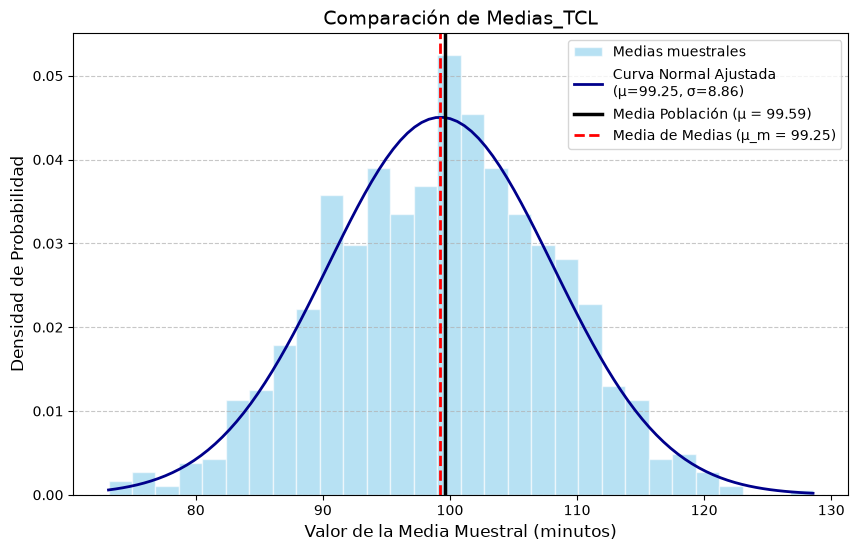

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

#nos ayuda a guardar en la carpeta outputs fuera de donde estamos trabajando
folder_path = os.path.join("..", "outputs")
os.makedirs(folder_path, exist_ok=True)


# media real de la población (calculada a partir de los datos originales)
media_poblacion =  df['Expected_Ride_Duration'].mean()

# 3. Graficar la distribución de las medias muestrales
plt.figure(figsize=(10, 6))

# Dibujar el histograma de las medias obtenidas
count, bins, ignored = plt.hist(medias_muestrales, bins=30, density=True, 
                                alpha=0.6, color='skyblue', edgecolor='white', 
                                label='Medias muestrales')

# Curva teórica Normal para verificar visualmente el ajuste empírico
mu_medias = np.mean(medias_muestrales)
sigma_medias = np.std(medias_muestrales)
x = np.linspace(min(medias_muestrales), max(medias_muestrales), 100)
plt.plot(x, stats.norm.pdf(x, mu_medias, sigma_medias), color='darkblue', 
         linewidth=2, label=f'Curva Normal Ajustada\n(μ={mu_medias:.2f}, σ={sigma_medias:.2f})')


## COMPARACIÓN DE MEDIAS 

# 1. Línea continua para la Media Poblacional Real (en negro o verde oscuro)
plt.axvline(media_poblacion, color='black', linestyle='-', linewidth=2.5, 
            label=f'Media Población (μ = {media_poblacion:.2f})')

# 2. Línea discontinua para la Media de Medias Muestrales (en rojo)
plt.axvline(mu_medias, color='red', linestyle='--', linewidth=2, 
            label=f'Media de Medias (μ_m = {mu_medias:.2f})')


# Personalización del gráfico
plt.title('Comparación de Medias_TCL', fontsize=14)
plt.xlabel('Valor de la Media Muestral (minutos)', fontsize=12)
plt.ylabel('Densidad de Probabilidad', fontsize=12)

# Colocamos la leyenda abajo o arriba a la derecha asegurando que se vean ambas etiquetas
plt.legend(loc='upper right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)



# Guardar y mostrar
filename = "Comparacion_Medias_TCL.png"
file_path = os.path.join(folder_path, filename)
plt.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()


## Intervalos de confianza

IC del 95% para la media de Expected_Ride_Duration. 

In [10]:
print(df['Expected_Ride_Duration'].describe()) # estadísticas descriptivas de la variable Expected_Ride_Duration

count    1000.00000
mean       99.58800
std        49.16545
min        10.00000
25%        59.75000
50%       102.00000
75%       143.00000
max       180.00000
Name: Expected_Ride_Duration, dtype: float64


In [11]:
df['Expected_Ride_Duration'].info() # información sobre la columna Expected_Ride_Duration

<class 'pandas.Series'>
RangeIndex: 1000 entries, 0 to 999
Series name: Expected_Ride_Duration
Non-Null Count  Dtype
--------------  -----
1000 non-null   int64
dtypes: int64(1)
memory usage: 7.9 KB


In [12]:
import numpy as np
import scipy.stats as stats

# Filtrar valores nulos si existen. Aunque vimos con el .info() que no hay, es una buena práctica para evitar errores en el cálculo de estadísticas.
duracion = df['Expected_Ride_Duration'].dropna()

# Calcular estadísticas necesarias
media_duracion = np.mean(duracion)
sem_duracion = stats.sem(duracion) # Error estándar de la media, que su formula es la desviación estándar de la muestra dividida 
# por la raíz cuadrada del tamaño de la muestra.

# Calcular el intervalo de confianza del 95%
ic_media = stats.t.interval(confidence=0.95, df=len(duracion)-1, loc=media_duracion, scale=sem_duracion) # el -1 es porque estamos usando la distribución
#t de Student, que requiere grados de libertad (n-1) para muestras pequeñas.

print(f"Media estimada: {media_duracion:.2f}")
print(f"Intervalo de confianza del 95% para la media: ({ic_media[0]:.2f} - {ic_media[1]:.2f})")


Media estimada: 99.59
Intervalo de confianza del 95% para la media: (96.54 - 102.64)


IC del 95% para la proporción de Average_Ratings excelente 
(≥4.0). 

In [13]:
df['Average_Ratings'].describe()

count    1000.000000
mean        4.257220
std         0.435781
min         3.500000
25%         3.870000
50%         4.270000
75%         4.632500
max         5.000000
Name: Average_Ratings, dtype: float64

In [14]:
df.head( )

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


In [15]:
%pip install statsmodels


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import pandas as pd
import numpy as np
import statsmodels.stats.proportion as prop

# Crear una variable binaria: 1 si es excelente (>= 4.0), 0 si no
ratings = df['Average_Ratings'].dropna()
exitos = np.sum(ratings >= 4.0)
total_observaciones = len(ratings)

# Calcular el intervalo de confianza del 95% (método Wilson score)
ic_proporcion = prop.proportion_confint(count=exitos, nobs=total_observaciones, alpha=0.05, method='wilson')

print(f"Proporción muestral: {exitos / total_observaciones:.4f}")
print(f"Intervalo de confianza del 95% para la proporción: ({ic_proporcion[0]:.4f} - {ic_proporcion[1]:.4f})")



Proporción muestral: 0.6860
Intervalo de confianza del 95% para la proporción: (0.6566 - 0.7140)


IC del 95% para la varianza de Historical_Cost_of_Ride. 

In [17]:
# Filtrar valores nulos
costos = df['Historical_Cost_of_Ride'].dropna() # en caso de que existan valores nulos, los eliminamos para evitar errores en el cálculo de la varianza y el intervalo de confianza.

n = len(costos)
varianza_muestral = np.var(costos, ddof=1) # Varianza con n-1 grados de libertad porque estamos estimando la varianza de la población a partir de una muestra.
# Valores críticos de Chi-cuadrado
alfa = 0.05
chi2_bajo = stats.chi2.ppf(alfa / 2, df=n-1)
chi2_alto = stats.chi2.ppf(1 - alfa / 2, df=n-1)

# Calcular límites del intervalo
ic_varianza_inf = ((n - 1) * varianza_muestral) / chi2_alto
ic_varianza_sup = ((n - 1) * varianza_muestral) / chi2_bajo

print(f"Varianza muestral: {varianza_muestral:.2f}")
print(f"Intervalo de confianza del 95% para la varianza: ({ic_varianza_inf:.2f} - {ic_varianza_sup:.2f})")


Varianza muestral: 35028.40
Intervalo de confianza del 95% para la varianza: (32148.63 - 38315.27)


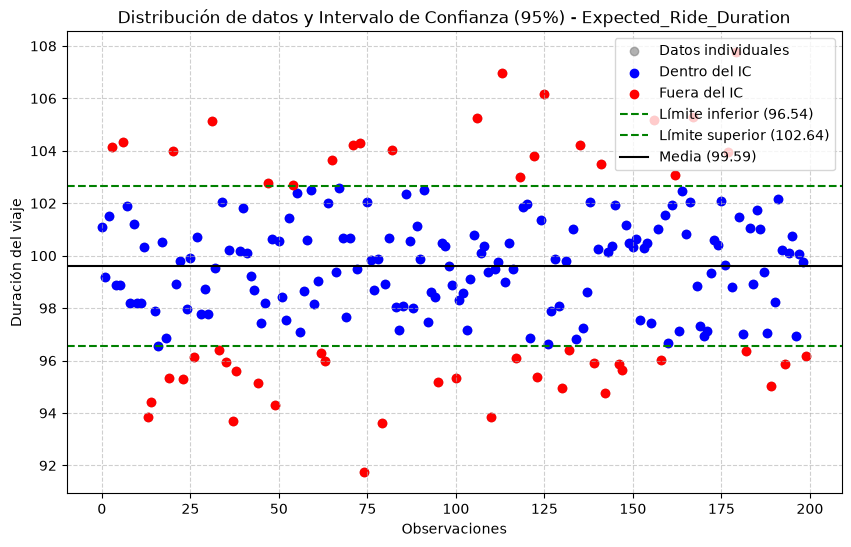

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Simulación de datos (usa tus datos reales del dataframe)
np.random.seed(42)
duracion = np.random.normal(99.59, 3, 200)  # media 99.59, desviación aprox. 3

# Intervalo de confianza calculado
ci_lower, ci_upper = 96.54, 102.64
media = 99.59

# Crear gráfico
plt.figure(figsize=(10,6))

# Puntos individuales
plt.scatter(range(len(duracion)), duracion, color='gray', alpha=0.6, label='Datos individuales')

# Puntos dentro del IC
inside = (duracion >= ci_lower) & (duracion <= ci_upper)
plt.scatter(np.where(inside)[0], duracion[inside], color='blue', label='Dentro del IC')

# Puntos fuera del IC
outside = ~inside
plt.scatter(np.where(outside)[0], duracion[outside], color='red', label='Fuera del IC')

# Líneas del intervalo y media
plt.axhline(ci_lower, color='green', linestyle='--', label=f'Límite inferior ({ci_lower})')
plt.axhline(ci_upper, color='green', linestyle='--', label=f'Límite superior ({ci_upper})')
plt.axhline(media, color='black', linestyle='-', label=f'Media ({media})')

plt.title('Distribución de datos y Intervalo de Confianza (95%) - Expected_Ride_Duration')
plt.xlabel('Observaciones')
plt.ylabel('Duración del viaje')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


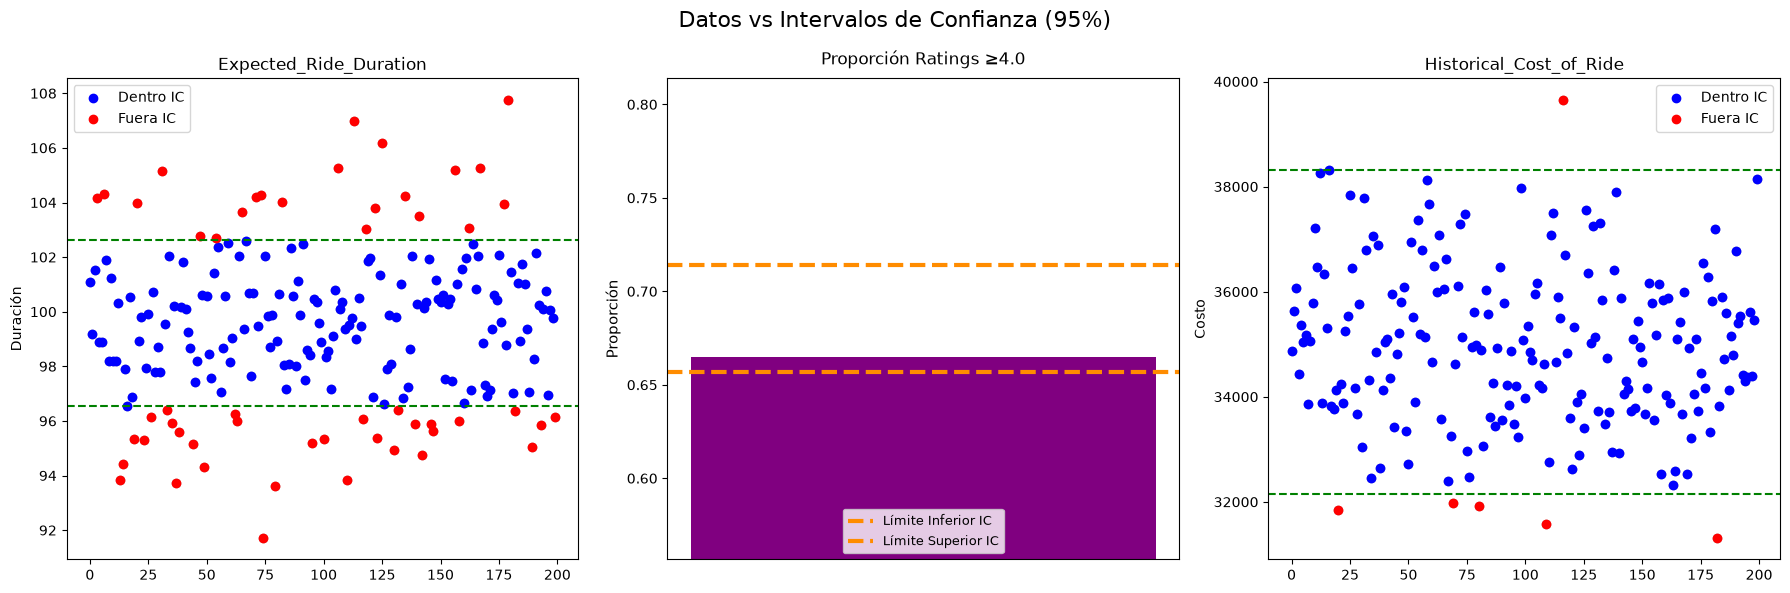

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Simulación de datos (usa tus datos reales del dataframe)
np.random.seed(42)
duracion = np.random.normal(99.59, 3, 200)  # Expected_Ride_Duration
ratings = np.random.binomial(1, 0.6860, 200)  # Average_Ratings ≥4.0 (proporción)
costos = np.random.normal(35028.40, 1500, 200)  # Historical_Cost_of_Ride

# Intervalos de confianza calculados
ci_duracion = (96.54, 102.64)
ci_ratings = (0.6566, 0.7140)
ci_costos = (32148.63, 38315.27)

# Crear lienzo con 3 subgráficas
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Datos vs Intervalos de Confianza (95%)', fontsize=16)

# --- Gráfico 1: Expected_Ride_Duration ---
inside = (duracion >= ci_duracion[0]) & (duracion <= ci_duracion[1])
axs[0].scatter(range(len(duracion)), duracion, color='gray', alpha=0.6)
axs[0].scatter(np.where(inside)[0], duracion[inside], color='blue', label='Dentro IC')
axs[0].scatter(np.where(~inside)[0], duracion[~inside], color='red', label='Fuera IC')
axs[0].axhline(ci_duracion[0], color='green', linestyle='--')
axs[0].axhline(ci_duracion[1], color='green', linestyle='--')
axs[0].set_title('Expected_Ride_Duration')
axs[0].set_ylabel('Duración')
axs[0].legend()

# --- Gráfico 2: Proporción Ratings ≥4.0 ---
# prop = ratings.mean()
# inside = (prop >= ci_ratings[0]) & (prop <= ci_ratings[1])
# axs[1].bar(0, prop, color='purple' if inside else 'red')
# axs[1].axhline(ci_ratings[0], color='yellow', linestyle='--')
# axs[1].axhline(ci_ratings[1], color='yellow', linestyle='--')
# axs[1].set_title('Proporción Ratings ≥4.0')
# axs[1].set_xticks([])
# axs[1].set_ylabel('Proporción')

prop = ratings.mean()
inside = (prop >= ci_ratings[0]) & (prop <= ci_ratings[1])

# Dibujar la barra principal
axs[1].bar(0, prop, color='purple' if inside else 'red', width=0.4)

# =========================================================================
# LÍNEAS DE INTERVALO OPTIMIZADAS (Más gruesas y con mejor contraste)
# =========================================================================
# Línea inferior (Grosor 3, estilo discontinuo largo, color naranja oscuro)
axs[1].axhline(ci_ratings[0], color='darkorange', linestyle='--', linewidth=3, label='Límite Inferior IC')

# Línea superior (Grosor 3, estilo discontinuo largo, color naranja oscuro)
axs[1].axhline(ci_ratings[1], color='darkorange', linestyle='--', linewidth=3, label='Límite Superior IC')

# Ajustes de formato del subgráfico
axs[1].set_title('Proporción Ratings ≥4.0', fontsize=12, pad=10)
axs[1].set_xticks([])
axs[1].set_ylabel('Proporción', fontsize=11)

# Ajuste dinámico del eje Y para centrar la atención en la barra y sus límites
axs[1].set_ylim(max(0, ci_ratings[0] - 0.1), min(1, ci_ratings[1] + 0.1))

# Opcional: Mostrar una leyenda para identificar qué significan las líneas
axs[1].legend(loc='lower center', fontsize=9)


# --- Gráfico 3: Historical_Cost_of_Ride ---
inside = (costos >= ci_costos[0]) & (costos <= ci_costos[1])
axs[2].scatter(range(len(costos)), costos, color='gray', alpha=0.6)
axs[2].scatter(np.where(inside)[0], costos[inside], color='blue', label='Dentro IC')
axs[2].scatter(np.where(~inside)[0], costos[~inside], color='red', label='Fuera IC')
axs[2].axhline(ci_costos[0], color='green', linestyle='--')
axs[2].axhline(ci_costos[1], color='green', linestyle='--')
axs[2].set_title('Historical_Cost_of_Ride')
axs[2].set_ylabel('Costo')
axs[2].legend()

plt.tight_layout()
plt.show()


In [20]:
df.head()

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


## Pruebas de Hipótesis para Comparación de Grupos 

Aplicar: Prueba t para comparar la media de Expected_Ride_Duration 
entre clientes con diferente Customer_Loyalty_Status (por ejemplo, 
Regular vs. Gold

In [21]:
## 2. Filtrar: Queremos los registros donde el Producto sea 'A' Y el Precio sea mayor a 20
#filtro = (df['Producto'] == 'A') & (df['Precio'] > 20)
#df_filtrado = df[filtro]

#print(df_filtrado)

In [22]:
filtro= df['Customer_Loyalty_Status'].isin(['Regular', 'Gold'])
df_filtrado = df[filtro]

df_filtrado

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422
6,93,43,Suburban,Regular,44,4.41,Afternoon,Premium,16,104.061541
7,62,39,Rural,Gold,83,3.59,Afternoon,Premium,47,235.811864
10,86,17,Urban,Regular,99,4.69,Morning,Economy,167,669.298626
...,...,...,...,...,...,...,...,...,...,...
995,33,23,Urban,Gold,24,4.21,Morning,Premium,11,91.389526
996,84,29,Urban,Regular,92,4.55,Morning,Premium,94,424.155987
997,44,6,Suburban,Gold,80,4.13,Night,Premium,40,157.364830
998,53,27,Suburban,Regular,78,3.63,Night,Premium,58,279.095048


In [23]:
import scipy.stats as stats

# 1. Filtrar los datos para cada grupo eliminando nulos
duracion_regular = df[df['Customer_Loyalty_Status'] == 'Regular']['Expected_Ride_Duration'].dropna()
duracion_gold = df[df['Customer_Loyalty_Status'] == 'Gold']['Expected_Ride_Duration'].dropna()

# 2. Ejecutar la prueba t para muestras independientes (equal_var=False aplica Welch)
t_stat, p_valor = stats.ttest_ind(duracion_regular, duracion_gold, equal_var=False)

print(f"Estadístico t: {t_stat:.4f}")
print(f"p-valor: {p_valor:.4f}")


Estadístico t: -0.2624
p-valor: 0.7931


 Prueba t para diferencias de proporciones en 
Average_Ratings (≥4.0) según Vehicle_Type (Economy vs. Premium). 
Presentar hipótesis nula y alternativa, estadístico de prueba, p-valor y 
conclusión. 

$$t = \frac{p_1 - p_2}{\sqrt{p(1-p)\left(\frac{1}{n_1} + \frac{1}{n_2}\right)}}$$

Donde:
* $p_1$ y $p_2$ son las proporciones muestrales.
* $n_1$ y $n_2$ son los tamaños de muestra.
* $p$ es la proporción combinada (*pooling*).


In [33]:
import numpy as np
from scipy import stats

# filtramos los datos por tipo de vehículo
ratings_economy = df[df['Vehicle_Type'] == 'Economy']['Average_Ratings'].dropna()
ratings_premium = df[df['Vehicle_Type'] == 'Premium']['Average_Ratings'].dropna()

# contamos los casos de éxitos (≥ 4.0) y totales
exitos_economy = np.sum(ratings_economy >= 4.0)
n_economy = len(ratings_economy)

exitos_premium = np.sum(ratings_premium >= 4.0)
n_premium = len(ratings_premium)

# proporciones muestrales
p1 = exitos_economy / n_economy
p2 = exitos_premium / n_premium

# Proporción combinada (pooling)
p_pool = (exitos_economy + exitos_premium) / (n_economy + n_premium)

# Estadístico t (equivalente a z en proporciones)
t_stat = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1/n_economy + 1/n_premium))

#  p-valor (bilateral)
p_valor = 2 * (1 - stats.norm.cdf(abs(t_stat)))

print(f"Proporción Economy: {p1:.4f}")
print(f"Proporción Premium: {p2:.4f}")
print(f"Estadístico t: {t_stat:.4f}")
print(f"p-valor: {p_valor:.4f}")


Proporción Economy: 0.6967
Proporción Premium: 0.6762
Estadístico t: 0.6946
p-valor: 0.4873


In [29]:
import numpy as np
import statsmodels.api as sm

# 1. Filtrar datos por tipo de vehículo
ratings_economy = df[df['Vehicle_Type'] == 'Economy']['Average_Ratings'].dropna()
ratings_premium = df[df['Vehicle_Type'] == 'Premium']['Average_Ratings'].dropna()

# 2. Contar éxitos (>= 4.0) y totales para cada grupo
exitos_economy = np.sum(ratings_economy >= 4.0)
n_economy = len(ratings_economy)

exitos_premium = np.sum(ratings_premium >= 4.0)
n_premium = len(ratings_premium)

# 3. Ejecutar la prueba z de proporciones
z_stat, p_valor_prop = sm.stats.proportions_ztest(
    count=[exitos_economy, exitos_premium], 
    nobs=[n_economy, n_premium]
)

print(f"Estadístico z: {z_stat:.4f}")
print(f"p-valor: {p_valor_prop:.4f}")


Estadístico z: 0.6946
p-valor: 0.4873


##  Pruebas de Varianza (F de Fisher) 

Evaluar si la varianza de Expected_Ride_Duration difiere 
significativamente entre dos grupos de Customer_Loyalty_Statu

In [25]:
import numpy as np
import scipy.stats as stats

# 1. Filtrar los datos para los dos grupos de lealtad
grupo_regular = df[df['Customer_Loyalty_Status'] == 'Regular']['Expected_Ride_Duration'].dropna()
grupo_gold = df[df['Customer_Loyalty_Status'] == 'Gold']['Expected_Ride_Duration'].dropna()

# 2. Calcular las varianzas muestrales
var_regular = np.var(grupo_regular, ddof=1)
var_gold = np.var(grupo_gold, ddof=1)

# 3. Calcular el estadístico F (se acostumbra poner la varianza mayor en el numerador)
if var_regular >= var_gold:
    f_stat = var_regular / var_gold
    dfn = len(grupo_regular) - 1  # Grados de libertad del numerador
    dfd = len(grupo_gold) - 1     # Grados de libertad del denominador
else:
    f_stat = var_gold / var_regular
    dfn = len(grupo_gold) - 1
    dfd = len(grupo_regular) - 1

# 4. Calcular el p-valor para una prueba de dos colas
p_valor = 2 * (1 - stats.f.cdf(f_stat, dfn, dfd))

print(f"Varianza Regular: {var_regular:.2f}, Varianza Gold: {var_gold:.2f}")
print(f"Estadístico F: {f_stat:.4f}")
print(f"p-valor: {p_valor:.4e}")

Varianza Regular: 2434.85, Varianza Gold: 2516.82
Estadístico F: 1.0337
p-valor: 7.6859e-01


##  Prueba Chi-Cuadrado 

Elaborar tabla de contingencia entre dos variables categóricas como: 
Customer_Loyalty_Status y Vehicle_Type. 

In [26]:
import pandas as pd
import scipy.stats as stats

# 1. Limpiar el dataset de filas con valores nulos en estas variables
df_limpio = df[['Customer_Loyalty_Status', 'Vehicle_Type']].dropna()

# 2. Elaborar la tabla de contingencia (frecuencias observadas)
tabla_contingencia = pd.crosstab(df_limpio['Customer_Loyalty_Status'], df_limpio['Vehicle_Type'])

print("--- Tabla de Contingencia (Valores Observados) ---")
print(tabla_contingencia)
print("\n" + "="*50 + "\n")

# 3. Aplicar la prueba de independencia Chi-Cuadrado
chi2_stat, p_valor, dof, frecuencias_esperadas = stats.chi2_contingency(tabla_contingencia)

print(f"Estadístico Chi-Cuadrado: {chi2_stat:.4f}")
print(f"Grados de libertad: {dof}")
print(f"p-valor: {p_valor:.4e}")

--- Tabla de Contingencia (Valores Observados) ---
Vehicle_Type             Economy  Premium
Customer_Loyalty_Status                  
Gold                         153      160
Regular                      144      176
Silver                       181      186


Estadístico Chi-Cuadrado: 1.4916
Grados de libertad: 2
p-valor: 4.7436e-01


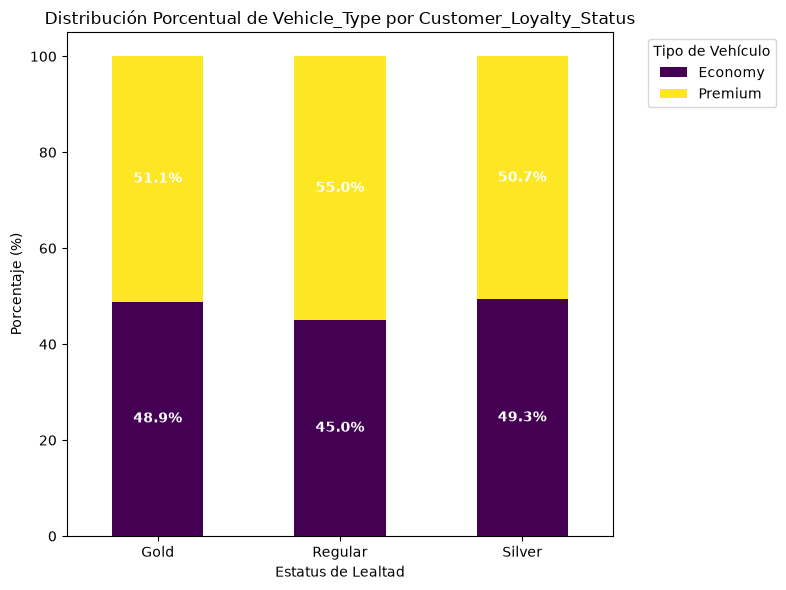

In [27]:
import matplotlib.pyplot as plt

# 1. Convertir la tabla de contingencia a porcentajes por fila (Normalizar)
tabla_porcentajes = pd.crosstab(
    df_limpio['Customer_Loyalty_Status'], 
    df_limpio['Vehicle_Type'], 
    normalize='index'
) * 100

# 2. Crear el gráfico de barras apiladas
ax = tabla_porcentajes.plot(kind='bar', stacked=True, figsize=(8, 6), cmap='viridis')

# 3. Personalizar detalles visuales
plt.title('Distribución Porcentual de Vehicle_Type por Customer_Loyalty_Status')
plt.xlabel('Estatus de Lealtad')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.legend(title='Tipo de Vehículo', bbox_to_anchor=(1.05, 1), loc='upper left')

# Añadir etiquetas de porcentaje dentro de las barras
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy() 
    if height > 0: # Solo mostrar si el porcentaje es mayor a cero
        ax.annotate(f'{height:.1f}%', (x + width/2, y + height/2), ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

## Análisis de Poder Estadístico y Errores Tipo I y II 

Calcular el poder estadístico de una de las pruebas t aplicadas, 
indicando: Tamaño del efecto estimado, Tamaño de muestra, Nivel de 
significancia. 
• Analizar los riesgos de cometer errores tipo I y tipo II y su impacto en 
decisiones organizacionales. 

In [28]:
import numpy as np
import statsmodels.stats.power as power

# 1. Obtener los datos reales antes usados
grupo_regular = df[df['Customer_Loyalty_Status'] == 'Regular']['Expected_Ride_Duration'].dropna()
grupo_gold = df[df['Customer_Loyalty_Status'] == 'Gold']['Expected_Ride_Duration'].dropna()

n_regular = len(grupo_regular) #Tamaños
n_gold = len(grupo_gold)

# 2. Calcular la d de Cohen (Tamaño del efecto)
media_reg, media_gold = np.mean(grupo_regular), np.mean(grupo_gold)
var_reg, var_gold = np.var(grupo_regular, ddof=1), np.var(grupo_gold, ddof=1)

# Desviación estándar mancomunada (Pooled SD)
sd_pooled = np.sqrt(((n_regular - 1) * var_reg + (n_gold - 1) * var_gold) / (n_regular + n_gold - 2))
d_cohen = abs(media_reg - media_gold) / sd_pooled

# 3. Calcular el Poder Estadístico
# Usamos TTestIndPower ya que comparamos dos grupos independientes
analisis_poder = power.TTestIndPower()

# Como los tamaños de muestra suelen ser diferentes en el negocio, calculamos la proporción de tamaños
ratio_muestras = n_gold / n_regular

poder = analisis_poder.solve_power(
    effect_size=d_cohen, 
    nobs1=n_regular, 
    ratio=ratio_muestras, 
    alpha=0.05, 
    alternative='two-sided'
)

print(f"--- Parámetros del Poder Estadístico ---")
print(f"Tamaño del efecto (d de Cohen): {d_cohen:.4f}")
print(f"Tamaño de muestra: Regular = {n_regular}, Gold = {n_gold}")
print(f"Nivel de significancia (Alpha): 0.05")
print(f"Poder Estadístico Calculado: {poder:.4f} (o {poder*100:.2f}%)")

--- Parámetros del Poder Estadístico ---
Tamaño del efecto (d de Cohen): 0.0209
Tamaño de muestra: Regular = 320, Gold = 313
Nivel de significancia (Alpha): 0.05
Poder Estadístico Calculado: 0.0579 (o 5.79%)
